# CoverWise — EDA and model evaluation

Exploratory analysis of the Medical Cost Personal Dataset plus a read-only review of the saved model-comparison reports. Stable logic lives in `src/`; this notebook only explores and explains.

> Educational project. Associations shown here are **not** causal.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.utils.config import load_config
from src.data.loader import load_raw, validate_dataframe
from src.evaluation.eda import iqr_outliers
sns.set_theme(style='whitegrid'); SEED = 42
cfg = load_config(); df = load_raw(cfg)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1. Data quality and schema audit

In [2]:
report = validate_dataframe(df, cfg)
print('Shape:', df.shape)
print('Validation problems:', report.problems or 'none')
print('Duplicate rows:', report.duplicate_rows)
print('Missing per column:', report.missing_per_column)
df.dtypes

Shape: (1338, 7)
Validation problems: none
Duplicate rows: 1
Missing per column: {'age': 0, 'sex': 0, 'bmi': 0, 'children': 0, 'smoker': 0, 'region': 0, 'charges': 0}


age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

**Finding.** The file has 1,338 rows and 7 columns, no missing values and one exact duplicate row. The duplicate is *kept*: with only six coarse attributes, two different people can legitimately share all values, and dropping it would change the data without evidence it is an error.

In [3]:
df.describe().round(2)

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


In [4]:
df[['sex','smoker','region']].apply(lambda s: s.value_counts(normalize=True).round(3)).T

,female,male,no,northeast,northwest,southeast,southwest,yes
sex,0.495,0.505,NaN,NaN,NaN,NaN,NaN,NaN
smoker,NaN,NaN,0.795,NaN,NaN,NaN,NaN,0.205
region,NaN,NaN,NaN,0.242,0.243,0.272,0.243,NaN


## 2. Target distribution and skew

In [5]:
t = cfg['dataset']['target']
print('skew(charges)      =', round(df[t].skew(), 3))
print('skew(log1p charges)=', round(np.log1p(df[t]).skew(), 3))
print('IQR outliers in charges:', iqr_outliers(df[t]))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df[t], bins=40, ax=ax[0]); ax[0].set(xlabel='Charges (USD)', title='Raw charges')
sns.histplot(np.log1p(df[t]), bins=40, ax=ax[1]); ax[1].set(xlabel='log(1 + charges)', title='Log scale')
plt.show()

skew(charges)      = 1.516
skew(log1p charges)= -0.09
IQR outliers in charges: {'lower_fence': -13109.1508975, 'upper_fence': 34489.350562499996, 'n_outliers': 139}


**Finding.** Charges are strongly right-skewed (skewness ≈ 1.52) and roughly symmetric after a log transform (≈ −0.09). 139 rows (about 10%) fall above the 1.5×IQR fence. These are **investigated, not removed**: 136 of the 139 are smokers, i.e. real structure rather than data errors. A log-target linear model was included as a candidate to test whether the skew needs special treatment (see section 5).

## 3. Relationships with charges

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=df, x='age', y=t, hue='smoker', alpha=.7, ax=ax[0]); ax[0].set(xlabel='Age (years)', ylabel='Charges (USD)', title='Age vs charges')
sns.scatterplot(data=df, x='bmi', y=t, hue='smoker', alpha=.7, ax=ax[1]); ax[1].axvline(30, ls='--', c='grey'); ax[1].set(xlabel='BMI (kg/m²)', ylabel='Charges (USD)', title='BMI vs charges')
plt.show()

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, c in zip(axes, ['smoker','region','sex']):
    sns.boxplot(data=df, x=c, y=t, ax=ax); ax.set(ylabel='Charges (USD)', title=f'Charges by {c}')
plt.show()
df.groupby('smoker')[t].agg(['count','mean','median']).round(0)

,count,mean,median
smoker,,,
no,1064,8434.0,7345.0
yes,274,32050.0,34456.0


In [8]:
df.groupby('region')[t].agg(['count','mean','median']).round(0)

,count,mean,median
region,,,
northeast,324,13406.0,10058.0
northwest,325,12418.0,8966.0
southeast,364,14735.0,9294.0
southwest,325,12347.0,8799.0


**Findings.**
- **Smoking** is the dominant separator: mean charges ≈ $32,050 for smokers vs ≈ $8,434 for non-smokers.
- **Age** shows several roughly parallel bands rising with age; of the 162 rows above $30,000, about 94% are smokers.
- **BMI** matters mainly for smokers: mean charges are ≈ $21.4k for smokers with BMI < 30 vs ≈ $41.6k with BMI ≥ 30, while non-smokers move only from ≈ $8.0k to ≈ $8.8k. That *interaction* is something a plain linear model cannot represent, which motivates tree-based models.
- **Region** differences in mean charges are modest (≈ $12.3k–$14.7k) relative to the spread within each region; **sex** differs little (medians ≈ $9.4k for both; the male mean is somewhat higher, ≈ $14.0k vs ≈ $12.6k, driven by the tail).
These are descriptive associations in one small dataset, not causal effects.

## 4. Correlation

In [9]:
corr = df.select_dtypes('number').corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues'); plt.title('Pearson correlation'); plt.show()

**Finding.** Linear correlation with charges is weak-to-moderate for age (≈ 0.30) and BMI (≈ 0.20) and very weak for children (≈ 0.07). Pearson correlation misses the smoker interaction above, so it understates how predictive these variables are *jointly*.

## 5. Preprocessing and model comparison (read from saved reports)

Preprocessing (median/most-frequent imputation, one-hot encoding, scaling for linear models only) lives inside scikit-learn `Pipeline`s, so it is fitted inside each CV fold. Nothing is recomputed here.

In [10]:
mc = json.loads((ROOT/'reports/model_comparison/model_comparison.json').read_text())
rows = [{'Model': m['model'], **{f"{k.upper()} mean": round(m['cv'][k]['mean'], 3 if k=='r2' else 0) for k in ('mae','rmse','r2')},
         **{f"{k.upper()} std": round(m['cv'][k]['std'], 3 if k=='r2' else 0) for k in ('mae','rmse','r2')}, 'Selected': m['selected']} for m in mc['models']]
pd.DataFrame(rows)

,Model,MAE mean,RMSE mean,R2 mean,MAE std,RMSE std,R2 std,Selected
0,Linear Regression,4270.0,6208.0,0.736,234.0,465.0,0.018,False
1,Linear Regression (log target),4335.0,8690.0,0.464,376.0,1068.0,0.192,False
2,Random Forest,2701.0,4860.0,0.838,352.0,653.0,0.029,False
3,Gradient Boosting,2649.0,4677.0,0.850,304.0,693.0,0.031,False
4,Random Forest (tuned),2603.0,4567.0,0.857,258.0,666.0,0.028,False
5,Gradient Boosting (tuned),2614.0,4527.0,0.859,280.0,702.0,0.030,True


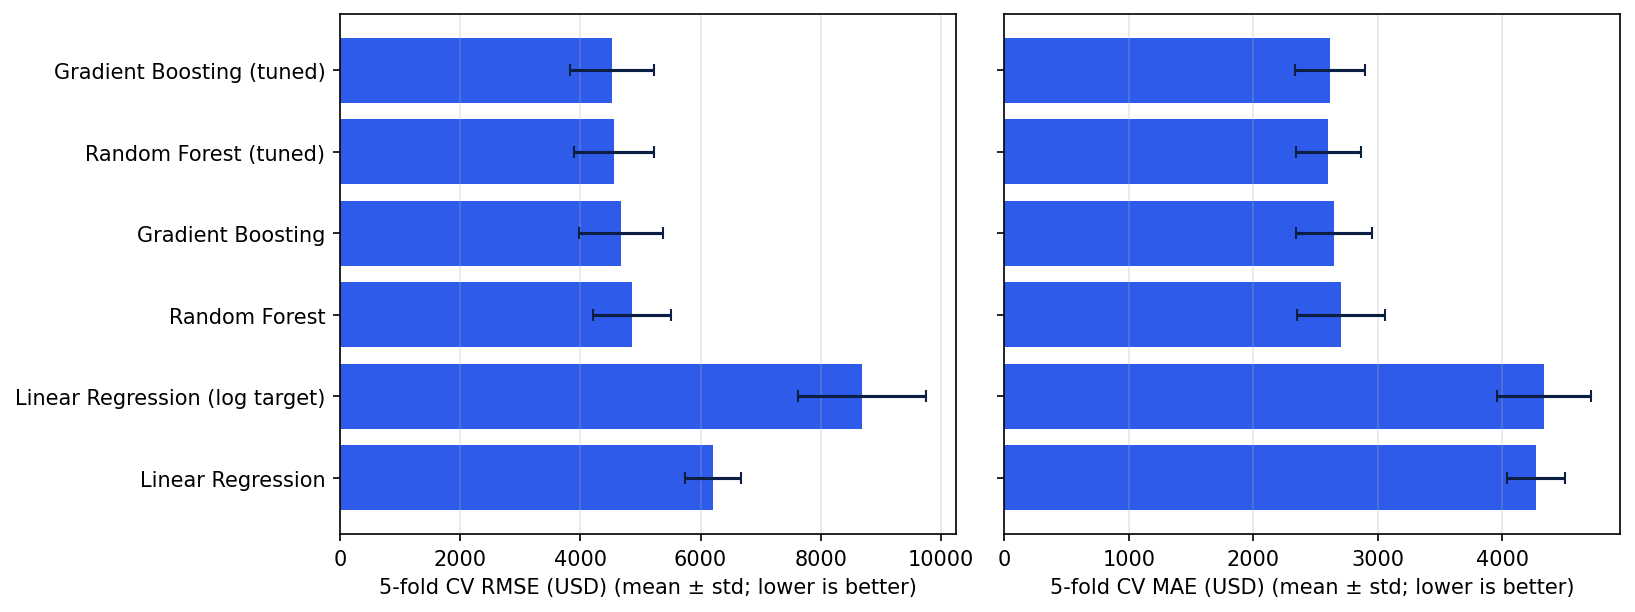

In [11]:
from IPython.display import Image
Image(str(ROOT/'reports/figures/model_comparison_cv.png'))

**Interpretation.** On identical shuffled 5-fold splits the tree-based models clearly beat the linear models. The log-target linear model is *worse* than the plain linear model on dollar-scale RMSE — transforming the target fixed the distribution's shape but did not improve dollar-scale error; a plausible (untested) reason is that errors on the log scale are amplified when converted back for high-cost cases, and the missing smoker × BMI interaction is likely the larger limitation of linear models. The tuned boosting and tuned random-forest models are within one fold-to-fold standard deviation of each other, so the choice between them is not clear-cut; gradient boosting was selected by the pre-declared rule (lowest mean CV RMSE).

## 6. Final hold-out test, residuals and subgroup errors

In [12]:
meta = json.loads((ROOT/'models/model_metadata.json').read_text())
print(meta['model_name'], meta['best_params'])
print('Hold-out:', {k: round(v, 3) for k, v in meta['holdout_metrics'].items()})
print('95% bootstrap CI:', {k: [round(x, 3) for x in v] for k, v in meta['holdout_metrics_95ci'].items()})

Gradient Boosting (tuned) {'model__learning_rate': 0.07853737079666878, 'model__max_depth': 3, 'model__min_samples_leaf': 3, 'model__n_estimators': 50, 'model__subsample': 1.0}
Hold-out: {'mae': 2418.129, 'rmse': 4166.261, 'r2': 0.882}
95% bootstrap CI: {'mae': [2023.111, 2826.369], 'rmse': [3250.77, 4970.402], 'r2': [0.821, 0.93]}


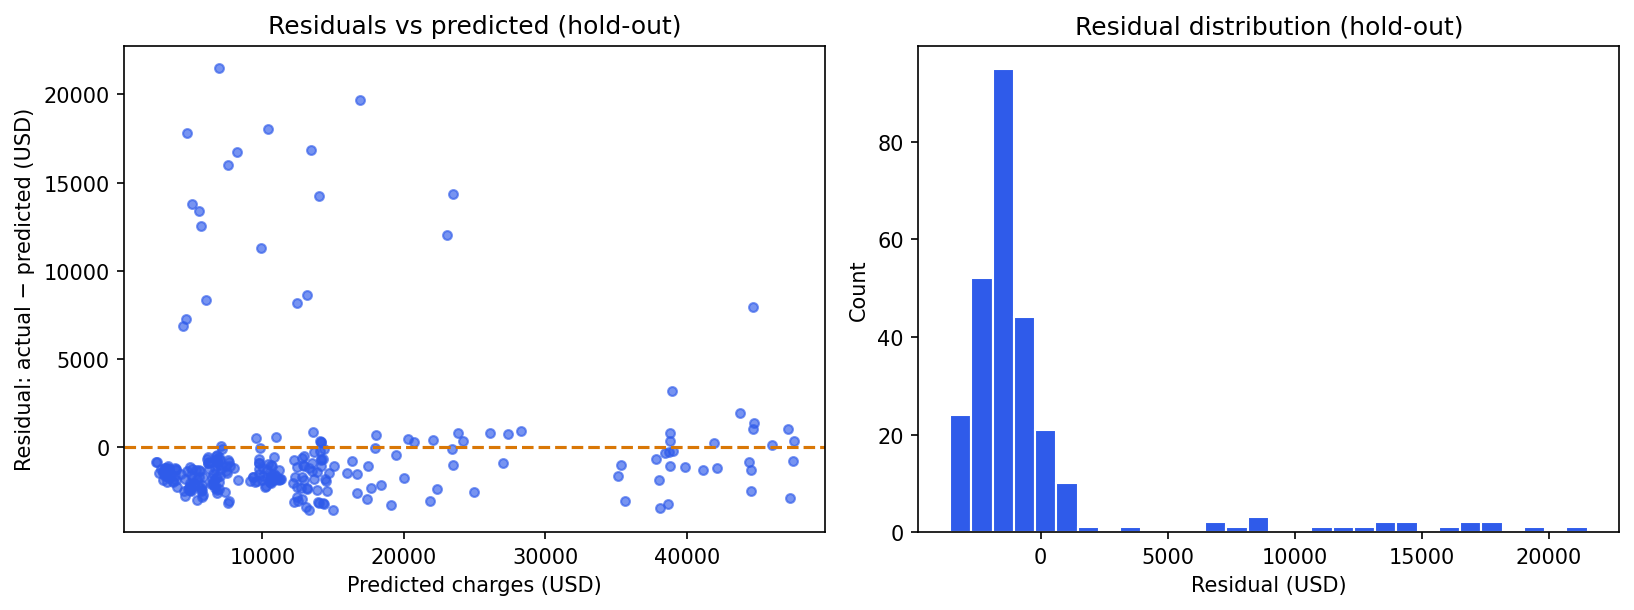

In [13]:
Image(str(ROOT/'reports/figures/holdout_residuals.png'))

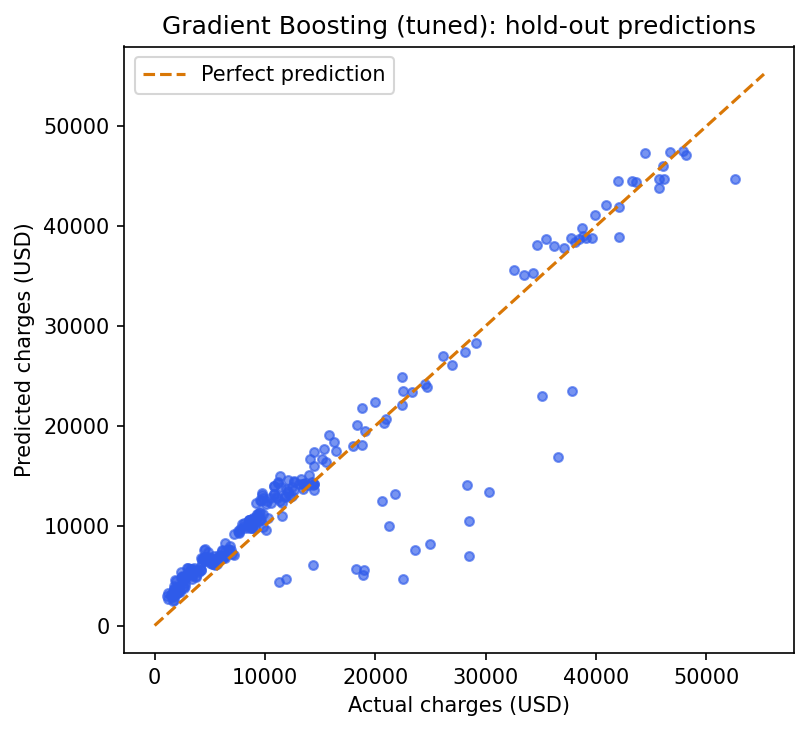

In [14]:
Image(str(ROOT/'reports/figures/holdout_predicted_vs_actual.png'))

In [15]:
pd.read_csv(ROOT/'reports/error_analysis/subgroup_errors.csv').round(1)

,group,level,n,mae,rmse,r2,mean_error,small_sample
0,sex,female,136,2163.0,3888.0,0.9,638.7,False
1,sex,male,132,2681.0,4434.7,0.9,-60.1,False
2,smoker,no,213,2559.8,4385.3,0.4,360.5,False
3,smoker,yes,55,1869.4,3178.9,0.9,38.9,False
4,region,northeast,62,2403.9,3938.9,0.9,521.1,False
5,region,northwest,65,2295.5,4673.3,0.8,-63.0,False
6,region,southeast,73,2660.8,4480.3,0.9,242.5,False
7,region,southwest,68,2287.9,3440.8,0.9,485.6,False
8,age_band,18-29,83,2463.6,3602.1,0.9,982.6,False
9,age_band,30-44,72,2335.9,4682.6,0.9,-270.4,False


**Notes.** Hold-out metrics come from 268 rows never used for selection or tuning. Subgroup rows with fewer than 30 records (e.g. BMI < 18.5) are flagged and should not be over-interpreted. Subgroup differences are signals to investigate, not a fairness certification.

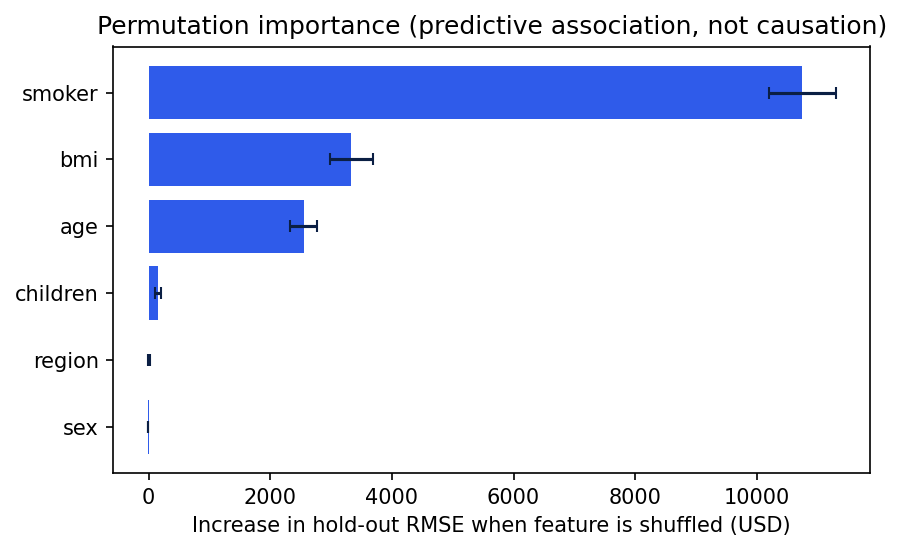

In [16]:
Image(str(ROOT/'reports/figures/permutation_importance.png'))

**Feature importance.** Permutation importance on the hold-out set ranks smoker status first, then BMI and age; children, region and sex contribute little to predictive accuracy. This describes what the model uses, not what causes costs.